# Synthetic survival curves

This executable notebook generates right-censored survival data, fits KESurv, and compares patient-specific survival curves with a population Kaplan–Meier curve. The random seed makes the example repeatable. Time is in arbitrary units.

## 1. Generate observed events and censoring

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from kesurv import KESurv
from sksurv.ensemble import RandomSurvivalForest
from sksurv.nonparametric import kaplan_meier_estimator
from sksurv.tree import SurvivalTree
from sksurv.util import Surv

rng = np.random.default_rng(2026)
n_subjects = 320
X = rng.normal(size=(n_subjects, 5))
latent_risk = 0.85 * X[:, 0] - 0.65 * X[:, 1] + 0.25 * X[:, 2]
event_time = rng.exponential(scale=2.5 * np.exp(-latent_risk))
censor_time = rng.exponential(scale=4.0, size=n_subjects)
event = event_time <= censor_time
observed_time = np.minimum(event_time, censor_time)
y = Surv.from_arrays(event, observed_time)
X_train, X_test = X[:250], X[250:]
y_train, y_test = y[:250], y[250:]
risk_test = latent_risk[250:]  # only for choosing examples to display
print(f'Training subjects: {len(X_train)}')
print(f'Observed event fraction: {y_train[y_train.dtype.names[0]].mean():.1%}')

Training subjects: 250
Observed event fraction: 58.8%


## 2. Fit the ensemble

The forest supplies local candidates. Two survival trees vote on whose predicted trajectories look similar to each query subject.

In [2]:
model = KESurv(
    base_estimators=[
        ('shallow', SurvivalTree(max_depth=3, random_state=11)),
        ('deep', SurvivalTree(max_depth=6, random_state=12)),
    ],
    forest=RandomSurvivalForest(
        n_estimators=60, min_samples_leaf=5, random_state=13
    ),
    epsilon=0.08,
    min_agreement=1,
    similarity_time=3.0,
    n_timepoints=64,
    backend='numpy',
    random_state=2026,
).fit(X_train, y_train)
print(f'Similarity grid: {len(model.similarity_times_)} points')
print(f'Event times in output: {len(model.unique_times_)}')

Similarity grid: 64 points
Event times in output: 147


## 3. See the survival curves

We select three held-out subjects using the **known synthetic latent risk** solely to make the plot easy to read. That risk is not supplied to KESurv. The dashed population curve ignores subject features.

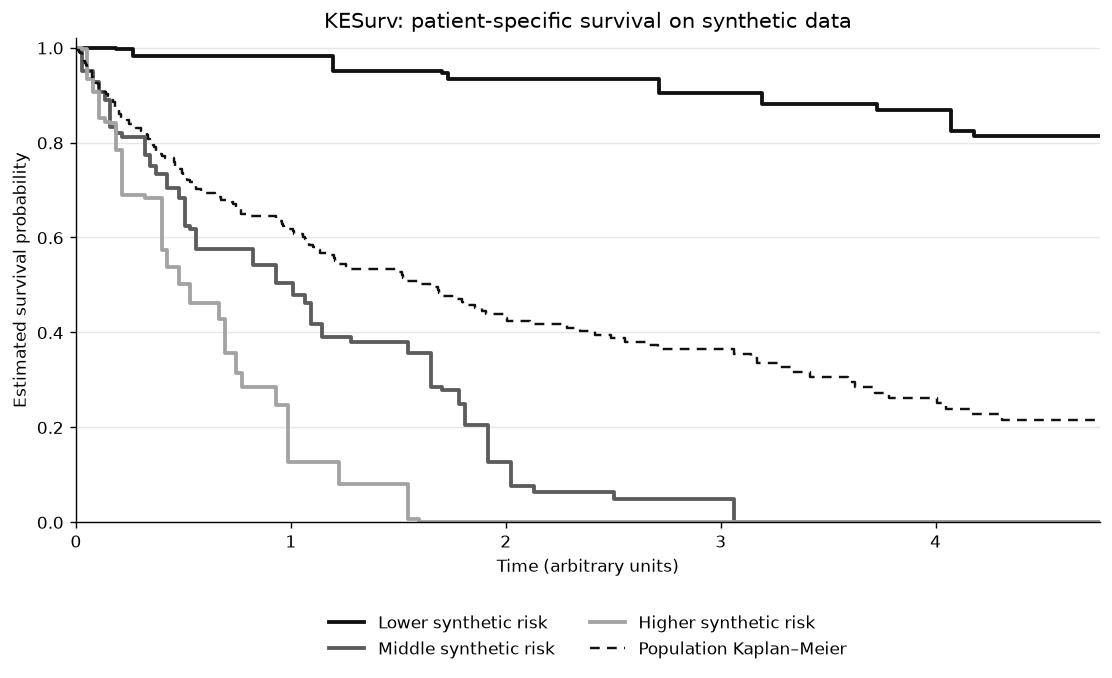

In [3]:
order = np.argsort(risk_test)
chosen = np.array([order[5], order[len(order) // 2], order[-6]])
horizon = float(np.quantile(y_train[y_train.dtype.names[1]], 0.95))
times = np.linspace(0.0, horizon, 180)
survival = model.predict_survival(X_test[chosen], times=times)
km_times, km_survival = kaplan_meier_estimator(
    y_train[y_train.dtype.names[0]], y_train[y_train.dtype.names[1]]
)

fig, ax = plt.subplots(figsize=(9, 5.6), dpi=125)
shades = ['#111111', '#5c5c5c', '#a3a3a3']
labels = ['Lower synthetic risk', 'Middle synthetic risk', 'Higher synthetic risk']
for row, (color, label) in enumerate(zip(shades, labels)):
    ax.step(times, survival[row], where='post', lw=2.2, color=color, label=label)
ax.step(km_times, km_survival, where='post', lw=1.4, ls=(0, (4, 3)),
        color='#111111', label='Population Kaplan–Meier')
ax.set(xlim=(0, horizon), ylim=(0, 1.02), xlabel='Time (arbitrary units)',
       ylabel='Estimated survival probability',
       title='KESurv: patient-specific survival on synthetic data')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e6e6e6')
ax.legend(frameon=False, loc='upper center', ncol=2,
          bbox_to_anchor=(0.5, -0.16))
fig.tight_layout()
plt.show()

## 4. Inspect one prediction

KESurv exposes selected neighbors, their weights, learner votes, and any fallback to the forest distribution.

In [4]:
info = model.predict_neighbor_info(X_test[chosen[-1:]])[0]
print(f'Forest candidates: {len(info["candidate_indices"])}')
print(f'Selected neighbors: {len(info["selected_indices"])}')
print(f'Fallback used: {info["fallback"]}')
print(f'Weight sum: {info["selected_weights"].sum():.3f}')
print(f'RMST through time 3: {model.predict_rmst(X_test[chosen[-1:]], 3.0)[0]:.3f}')

Forest candidates: 90
Selected neighbors: 35
Fallback used: False
Weight sum: 1.000
RMST through time 3: 0.589


These results illustrate API behavior on generated data. They are not a clinical validation or a reproduction of the paper's benchmark tables. To rerun the notebook after changing the package, use `python examples/build_synthetic_notebook.py`.